Gradient Descent function

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm

In [18]:
import numpy as np

def gradient_descent(X, y, lr=0.01, iter=10000):
    X = np.c_[np.ones(X.shape[0]), X]
    beta = np.zeros(X.shape[1])
    losses = []
    n = len(y)

    for i in range(iter):
        y_pred= X@beta
        gradient = (2/n) * X.T @ (y_pred-y)
        beta = beta - lr * gradient
        loss = np.mean((X @ beta - y) ** 2)
        losses.append(loss)
    return beta,losses

def predict(X, beta):
    X_1 = np.c_[np.ones(X.shape[0]), X]
    return X_1 @ beta

def evaluate(y, y_pred):
    mse = np.mean((y_pred - y) ** 2)
    r_squared = 1 - mse / np.var(y)
    return mse, r_squared

In [20]:
file_path = "concrete+compressive+strength/Concrete_Data.xls"

df = pd.read_excel(file_path)

print(df.shape)
df.head()

(1030, 9)


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [21]:
X = df.iloc[:, :8]
y = df.iloc[:, 8]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1030, 8)
y shape: (1030,)


In [22]:
train_idx = np.r_[0:500, 630:1030]
X_train = X.iloc[train_idx].copy()
y_train = y.iloc[train_idx].copy()
X_test = X[500:630]
y_test = y[500:630]

print("Training:", X_train.shape, y_train.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (900, 8) (900,)
Testing: (130, 8) (130,)


In [23]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std = np.where(std == 0, 1, std)
X_train_stand = (X_train - mean) / std
X_test_stand = (X_test - mean) / std


X_train_log = np.log1p(X_train)
X_test_log = np.log1p(X_test)

Q3 Scaling

In [28]:
#Q3.1 train a multivariate model using untransformed features

lr_untrans=5e-8
iter=10000

beta_raw, loss_raw = gradient_descent(
    X_train.values, y_train.values, lr_untrans, iter
)

train_mse, train_r2 = evaluate(
    y_train.values, predict(X_train.values, beta_raw)
)
test_mse, test_r2 = evaluate(
    y_test.values, predict(X_test.values, beta_raw)
)

print("Untransformed Model")
print(f"Train: MSE = {train_mse:.4f}, R² = {train_r2:.4f}")
print(f"Test:  MSE = {test_mse:.4f}, R² = {test_r2:.4f}")

Untransformed Model
Train: MSE = 115.6933, R² = 0.5824
Test:  MSE = 152.0167, R² = 0.3207


In [33]:
#Q3.1 train a multivariate model using standardized features

lr_stand=0.01
iter=10000

beta_stand, loss_stand = gradient_descent(
    X_train_stand, y_train.values, lr_stand, iter
)

train_mse_stand, train_r2_stand = evaluate(
    y_train.values, predict(X_train_stand, beta_stand)
)
test_mse_stand, test_r2_stand = evaluate(
    y_test.values, predict(X_test_stand, beta_stand)
)

print("Standardized Model")
print(f"Train: MSE = {train_mse_stand:.4f}, R² = {train_r2_stand:.4f}")
print(f"Test:  MSE = {test_mse_stand:.4f}, R² = {test_r2_stand:.4f}")

Standardized Model
Train: MSE = 104.1439, R² = 0.6240
Test:  MSE = 141.2325, R² = 0.3688


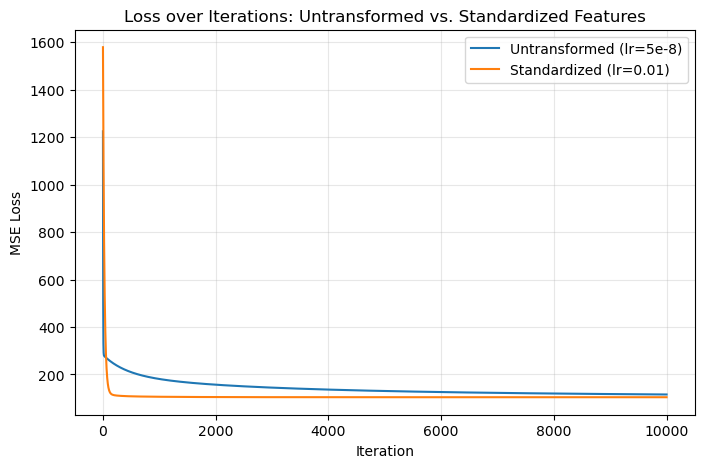

In [31]:
#Q3.1 plot

plt.figure(figsize=(8, 5))
plt.plot(loss_raw, label="Untransformed (lr=5e-8)")
plt.plot(loss_stand, label="Standardized (lr=0.01)")

plt.xlabel("Iteration")
plt.ylabel("MSE Loss")
plt.title("Loss over Iterations: Untransformed vs. Standardized Features")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("scaling_convergence.png", dpi=300, bbox_inches="tight")
plt.show()

Q5 Non-Linear Transformations

In [35]:
#Q5.1 log-transformed multivariate model

lr_log = 0.001
iter = 10000

beta_log, loss_log = gradient_descent(
    X_train_log, y_train.values, lr_log, iter=10000
)

train_mse_log, train_r2_log = evaluate(
    y_train.values, predict(X_train_log, beta_log)
)
test_mse_log, test_r2_log = evaluate(
    y_test.values, predict(X_test_log, beta_log)
)

print("Log-Transformed Model")
print(f"Train: MSE = {train_mse_log:.4f}, R² = {train_r2_log:.4f}")
print(f"Test:  MSE = {test_mse_log:.4f}, R² = {test_r2_log:.4f}")

Log-Transformed Model
Train: MSE = 66.5257, R² = 0.7598
Test:  MSE = 55.5716, R² = 0.7517


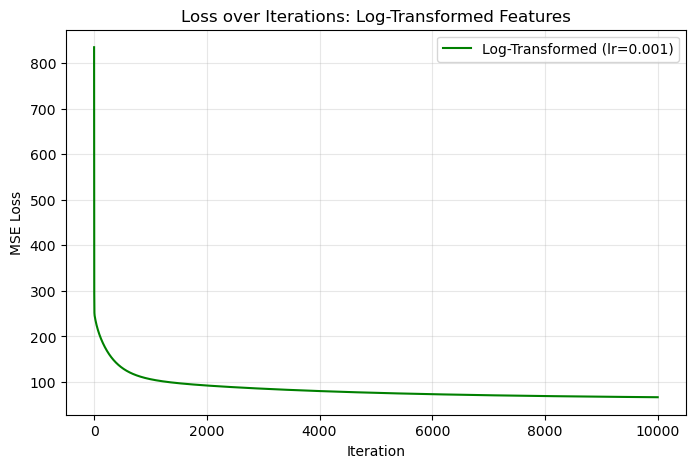

In [36]:
# Q5.1 figure showing loss over iterations

plt.figure(figsize=(8, 5))
plt.plot(loss_log, color="green", label="Log-Transformed (lr=0.001)")

plt.xlabel("Iteration")
plt.ylabel("MSE Loss")
plt.title("Loss over Iterations: Log-Transformed Features")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("5104_Q5.1.png", dpi=300, bbox_inches="tight")
plt.show()

Report data analysis

In [39]:
# Table 1. Descriptive Statistics

train_data = X_train.copy()
train_data["Compressive Strength"] = y_train

summary = train_data.agg(["mean", "std", "min", "max"]).T
summary.columns = ["Mean", "SD", "Min", "Max"]
summary.index = [
    "Cement", "Blast Furnace Slag", "Fly Ash", "Water",
    "Superplasticizer", "Coarse Aggregate", "Fine Aggregate",
    "Age", "Compressive Strength"
]

display(summary.round(2))
summary.round(2).to_csv("Table1_Descriptive_Statistics.csv")

,Mean,SD,Min,Max
Cement,277.87,106.00,102.00,540.0
Blast Furnace Slag,76.11,84.07,0.00,305.3
Fly Ash,57.38,64.26,0.00,200.1
Water,180.72,22.28,121.75,247.0
Superplasticizer,6.86,5.98,0.00,32.2
Coarse Aggregate,973.76,77.57,801.00,1145.0
Fine Aggregate,772.33,81.91,594.00,992.6
Age,46.04,61.32,1.00,365.0
Compressive Strength,36.93,16.65,2.33,82.6


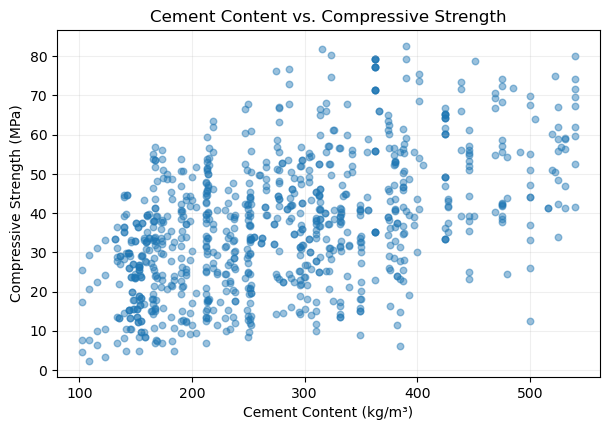

In [42]:
# Figure 1. Cement Content vs. Compressive Strength

plt.figure(figsize=(7, 4.5))
plt.scatter(X_train.iloc[:, 0], y_train, alpha=0.45, s=22)

plt.xlabel("Cement Content (kg/m³)")
plt.ylabel("Compressive Strength (MPa)")
plt.title("Cement Content vs. Compressive Strength")
plt.grid(alpha=0.2)

plt.show()

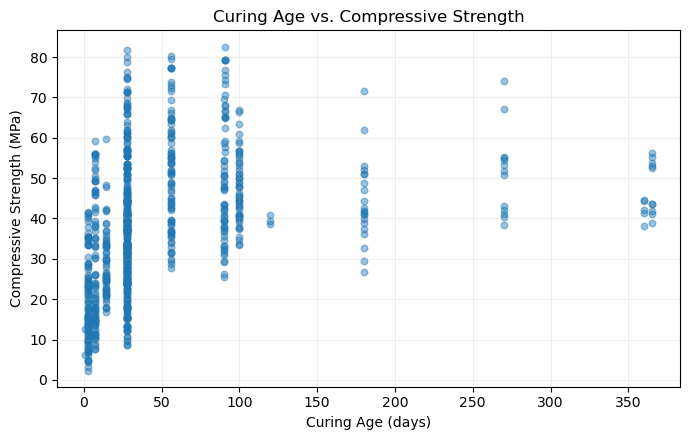

In [43]:
# Figure 2. Curing Age vs. Compressive Strength

plt.figure(figsize=(7, 4.5))
plt.scatter(X_train.iloc[:, 7], y_train, alpha=0.45, s=22)

plt.xlabel("Curing Age (days)")
plt.ylabel("Compressive Strength (MPa)")
plt.title("Curing Age vs. Compressive Strength")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

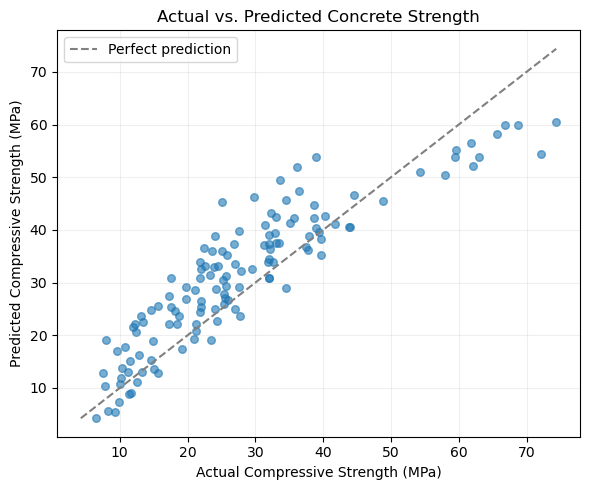

In [45]:
# Figure 3. Actual vs. Predicted Concrete Strength

y_pred = model_log.predict(np.log1p(X_test))

plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.6, s=30)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "--", color="gray", label="Perfect prediction")

plt.xlabel("Actual Compressive Strength (MPa)")
plt.ylabel("Predicted Compressive Strength (MPa)")
plt.title("Actual vs. Predicted Concrete Strength")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()